# 04 · Análise visual e primeiras respostas
**Etapa planejada: 20–23/10/2026 · executada antecipadamente em 16/10/2026.**

Este notebook continua a integração de 17–19/10. Produz gráficos e tabelas das perguntas 1–6 e a primeira sensibilidade da pergunta 7 (mínimo de três notícias). A leitura acadêmica está em [00_artigo.ipynb](00_artigo.ipynb); aqui cada transformação vem acompanhada de sua explicação.

**Antes de comparar:** H1 prevê cobertura desigual; H2 explora intensidade do sentimento e retorno absoluto; H3 explora diferenças entre empresas/anos. São hipóteses exploratórias já documentadas, sem pré-registro formal. As decisões estão em `docs/config_analise_visual.json`, criado antes dos novos cálculos. Não selecionamos filtros conforme o sinal encontrado.

O pacote do grupo inclui as entradas fixadas. Em outro clone, execute 01 → 02 → 03 ou obtenha os mesmos snapshots. Este notebook funciona sem rede e sem executar FinBERT. Não troca silenciosamente os dados por outra coleta: a primeira célula confere hashes. Em nova execução com entradas diferentes, revise e versione a configuração e a narrativa.

## 1. Ambiente, arquivos e funções de apresentação
`Path` permite localizar a raiz tanto a partir de `notebooks/` quanto da pasta do projeto. O hash confere os bytes das entradas. As funções abaixo evitam repetir a mesma formatação em cada figura. `spearman` calcula a correlação de Pearson dos postos médios: empates recebem o posto médio; grupos constantes ou insuficientes ficam sem coeficiente. Não calculamos p-valores nem inferência de causalidade.

In [1]:
from pathlib import Path
import hashlib, json, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'docs/config_analise_visual.json').exists():
    ROOT = ROOT.parent
CONFIG = json.loads((ROOT/'docs/config_analise_visual.json').read_text(encoding='utf-8'))
DATA = ROOT/'data/processed'
FIG = ROOT/'figures/analise_visual'
TAB = ROOT/'docs/analise_visual'
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
for nome, esperado in CONFIG['sha256_entradas'].items():
    assert hashlib.sha256((DATA/nome).read_bytes()).hexdigest() == esperado, nome

EMPRESAS = ['BAC', 'JNJ', 'KO', 'NFLX', 'NVDA']
CLASSES = ['negativo', 'neutro', 'positivo', 'empate']
CORES = {'negativo':'#BD5B3A', 'neutro':'#83929F', 'positivo':'#16877B', 'empate':'#9B79AF'}
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.titleweight':'bold', 'axes.labelcolor':'#263647',
                     'savefig.facecolor':'white'})
figuras = []
def salvar(fig, nome, titulo, nota):
    fig.suptitle(titulo, fontsize=15, fontweight='bold', x=0.07, ha='left')
    fig.text(0.07, 0.015, nota, fontsize=8.4, color='#475569')
    fig.tight_layout(rect=[0.02, 0.06, 0.99, 0.94])
    fig.savefig(FIG/f'{nome}.png', dpi=160)
    figuras.append(nome)
    plt.show()
    plt.close(fig)

def spearman(df, x, y):
    pares = df[[x,y]].dropna()
    if len(pares)<3 or pares[x].nunique()<2 or pares[y].nunique()<2:
        return float('nan')
    postos = pares.rank(method='average')
    return float(postos[x].corr(postos[y], method='pearson'))

print('Entradas conferidas; saídas em', FIG.relative_to(ROOT), 'e', TAB.relative_to(ROOT))

Entradas conferidas; saídas em figures\analise_visual e docs\analise_visual


## 2. Ler e conferir as unidades
`parse_dates` transforma as datas em objetos temporais; `duplicated` protege as chaves. A tabela `noticias` responde às perguntas de cobertura e tom. O `painel` contém um único retorno por empresa/pregão. `mapeadas` é usada para auditoria, nunca como se cada manchete fosse um retorno independente. Conferimos probabilidades, escores e a regra de retorno sem modificar as entradas.

In [2]:
noticias = pd.read_csv(DATA/'noticias_com_sentimento.csv', parse_dates=['news_date'])
painel = pd.read_csv(DATA/'base_integrada_pregoes.csv', parse_dates=['trade_date'])
mapeadas = pd.read_csv(DATA/'noticias_pregao_retornos.csv', parse_dates=['news_date','trade_date'])
assert len(noticias)==len(mapeadas)==6552 and len(painel)==3770
assert not noticias.duplicated(['stock','news_date','headline']).any()
assert not painel.duplicated(['stock','trade_date']).any()
assert set(noticias['stock'])==set(EMPRESAS)==set(painel['stock'])
assert noticias['classe_finbert'].isin(CLASSES).all()
assert np.allclose(noticias[['p_positivo','p_neutro','p_negativo']].sum(axis=1), 1, atol=1e-6)
assert np.allclose(noticias['escore_sentimento'], noticias['p_positivo']-noticias['p_negativo'], atol=1e-8)
assert (mapeadas['trade_date'] > mapeadas['news_date']).all()
assert np.allclose(painel['retorno_pct'], 100*(painel['adj_close']/painel['adj_close_anterior']-1), atol=1e-7)
assert np.allclose(painel['retorno_absoluto_pct'], painel['retorno_pct'].abs())
assert painel.loc[~painel['tem_noticias'], 'escore_sentimento'].isna().all()
print('6.552 associações; 3.770 pares empresa/pregão; chaves e fórmulas conferidas.')

6.552 associações; 3.770 pares empresa/pregão; chaves e fórmulas conferidas.


## 3. Selecionar a amostra principal e explicitar perdas
Uma máscara booleana combina condições com `&`. `loc[mascara].copy()` cria uma tabela de análise independente. Excluímos das comparações com retornos somente ausência de notícias e janela incompleta, conforme a etapa 03. A contagem por empresa permitirá avaliar se os resultados têm bases muito diferentes. `ano` é o ano do pregão de resposta, não o da manchete.

In [3]:
principal = painel.loc[painel['tem_noticias'] & painel['elegivel_analise_principal']].copy()
principal['ano'] = principal['trade_date'].dt.year
assert len(principal)==2387
assert principal[['escore_sentimento','intensidade_sentimento','retorno_pct','retorno_absoluto_pct']].notna().all().all()
assert principal['classe_sentimento'].isin(CLASSES).all()
amostras = painel.groupby('stock').agg(painel=('trade_date','size'), com_noticias=('tem_noticias','sum'))
amostras['principal'] = principal.groupby('stock').size()
amostras['minimo_3'] = principal.loc[principal['n_noticias'].ge(3)].groupby('stock').size()
amostras['retencao_pct'] = 100*amostras['minimo_3']/amostras['principal']
amostras['sem_noticias'] = amostras['painel']-amostras['com_noticias']
amostras['com_noticias_janela_incompleta'] = amostras['com_noticias']-amostras['principal']
display(amostras.round(2))

,painel,com_noticias,principal,minimo_3,retencao_pct,sem_noticias,com_noticias_janela_incompleta
stock,,,,,,,
BAC,754,438,438,88,20.09,316,0
JNJ,754,446,446,123,27.58,308,0
KO,754,335,334,58,17.37,419,1
NFLX,754,628,627,307,48.96,126,1
NVDA,754,543,542,207,38.19,211,1


## 4. Pergunta 1 · Cobertura mensal e total
`to_period('M')` agrupa datas pelo mês; `groupby(...).size()` conta linhas. `unstack` transforma meses em colunas. Reindexar os 36 meses e preencher a **contagem** com zero explicita lacunas no corpus. Aqui zero significa nenhuma notícia registrada; não é um escore neutro. O mapa usa uma escala comum e as barras começam em zero.

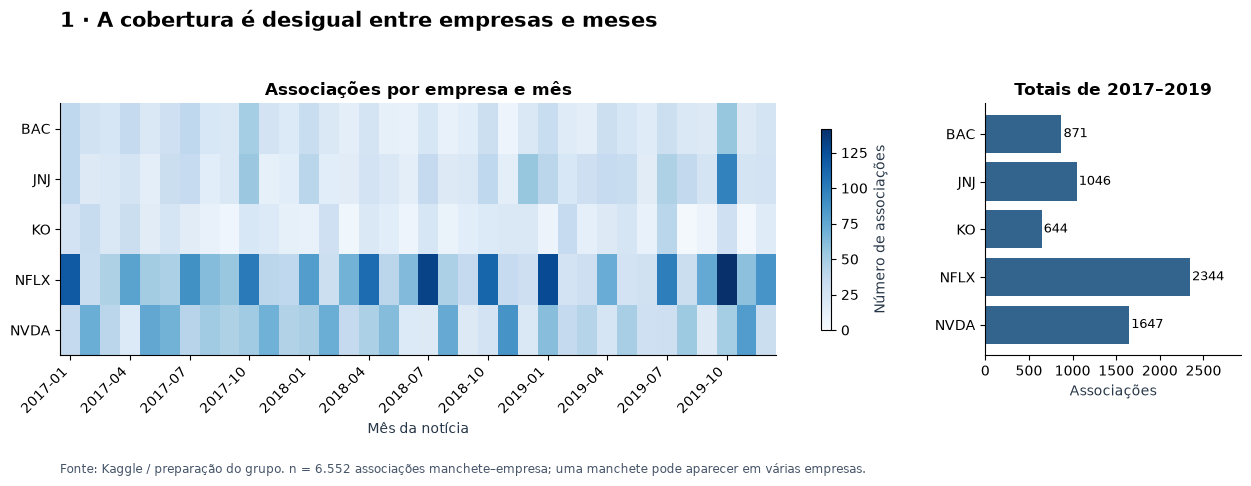

,n_associacoes
stock,
BAC,871
JNJ,1046
KO,644
NFLX,2344
NVDA,1647


In [4]:
meses = pd.period_range('2017-01','2019-12',freq='M')
cobertura = (noticias.assign(mes=noticias['news_date'].dt.to_period('M'))
             .groupby(['stock','mes']).size().unstack('mes')
             .reindex(index=EMPRESAS,columns=meses).fillna(0).astype(int))
totais = cobertura.sum(axis=1)
assert totais.sum()==len(noticias)
fig, (ax, barras) = plt.subplots(1,2,figsize=(13,4.8),gridspec_kw={'width_ratios':[3.5,1]})
im = ax.imshow(cobertura.to_numpy(), cmap='Blues', aspect='auto', vmin=0)
ax.set_yticks(range(5), EMPRESAS)
ax.set_xticks(range(0,36,3), [str(m) for m in meses[::3]], rotation=45, ha='right')
ax.set_xlabel('Mês da notícia'); ax.set_title('Associações por empresa e mês')
fig.colorbar(im,ax=ax,label='Número de associações',shrink=0.8)
barras.barh(EMPRESAS,totais,color='#32648D'); barras.invert_yaxis()
for i,v in enumerate(totais): barras.text(v+25,i,str(v),va='center',fontsize=9)
barras.set_xlim(0,totais.max()*1.25); barras.set_title('Totais de 2017–2019'); barras.set_xlabel('Associações')
salvar(fig,'q1_cobertura','1 · A cobertura é desigual entre empresas e meses',
       'Fonte: Kaggle / preparação do grupo. n = 6.552 associações manchete–empresa; uma manchete pode aparecer em várias empresas.')
display(totais.rename('n_associacoes').to_frame())

**Atualização de 16/10.** O notebook 04 reproduziu a contagem das 6.552 associações e o mapa mensal, acrescentando barras com os totais. A versão com os dois painéis está em [cobertura mensal e totais](../figures/analise_visual/q1_cobertura.png). O resultado permanece consistente com H1; cobertura é uma característica do corpus, sem explicar o comportamento dos preços.

## 5. Pergunta 2 · Proporções dentro de cada empresa
`crosstab` conta classes. Dividir por `sum(axis=1)` com `axis=0` usa o total de cada empresa como denominador. Assim, uma empresa com mais notícias não parece mais positiva apenas por ter maior cobertura. Mantemos a categoria empate mesmo se tiver contagem zero. Cada barra soma 100%.

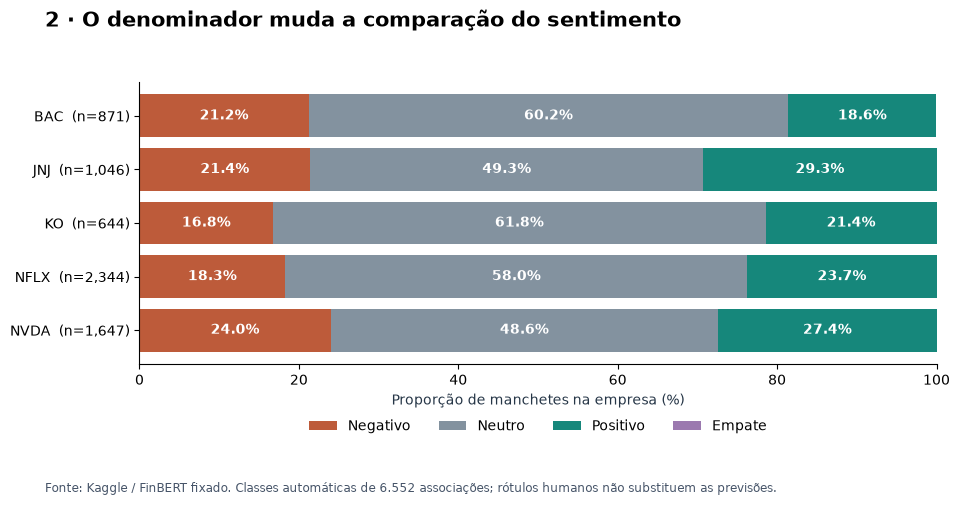

classe_finbert,negativo,neutro,positivo,empate
stock,,,,
BAC,21.24,60.16,18.60,0.0
JNJ,21.41,49.33,29.25,0.0
KO,16.77,61.80,21.43,0.0
NFLX,18.30,57.98,23.72,0.0
NVDA,23.98,48.63,27.38,0.0


In [5]:
classes = pd.crosstab(noticias['stock'], noticias['classe_finbert']).reindex(index=EMPRESAS,columns=CLASSES,fill_value=0)
proporcoes = classes.div(classes.sum(axis=1),axis=0)*100
assert np.allclose(proporcoes.sum(axis=1),100)
fig,ax=plt.subplots(figsize=(10,5))
base=np.zeros(5)
for classe in CLASSES:
    valores=proporcoes[classe].to_numpy()
    ax.barh(EMPRESAS,valores,left=base,color=CORES[classe],label=classe.capitalize())
    for i,v in enumerate(valores):
        if v>=6: ax.text(base[i]+v/2,i,f'{v:.1f}%',ha='center',va='center',color='white',fontweight='bold')
    base+=valores
ax.set_yticks(range(5),[f'{e}  (n={classes.loc[e].sum():,})' for e in EMPRESAS])
ax.invert_yaxis(); ax.set_xlim(0,100); ax.set_xlabel('Proporção de manchetes na empresa (%)')
ax.legend(ncols=4,loc='upper center',bbox_to_anchor=(0.5,-0.15),frameon=False)
salvar(fig,'q2_composicao','2 · O denominador muda a comparação do sentimento',
       'Fonte: Kaggle / FinBERT fixado. Classes automáticas de 6.552 associações; rótulos humanos não substituem as previsões.')
display(proporcoes.round(2))

**Resultado e interpretação.** Neutro é a classe mais frequente nas cinco empresas, mas não supera 50% em JNJ e NVDA. KO tem a maior proporção neutra (61,8%), JNJ a maior positiva (29,3%) e NVDA a maior negativa (24,0%). BAC apresenta 18,6% de positivas e 21,2% de negativas. Comparar proporções dentro de cada empresa evita confundir cobertura com composição do sentimento. Não houve empate nas classes por manchete.

**Limitação.** O modelo classifica o texto inteiro e pode transferir o tom de uma manchete sobre várias empresas a todos os tickers vinculados. A revisão dirigida de 50 casos não estima a acurácia geral, e as classes não são uma verdade observada sem erro.

## 6. Pergunta 3 · Escore por data civil
Agrupamos as manchetes por empresa/data e calculamos média e contagem. Os pontos mostram **somente datas com notícias**, em escala comum de −1 a 1. O tamanho representa a contagem, com a mesma fórmula em todos os painéis. Não ligamos dias sem registros. Extremos são mínimo e máximo diário por empresa, com desempate pela primeira data; selecionar extremos serve à descrição, não à comprovação de H2 ou H3.

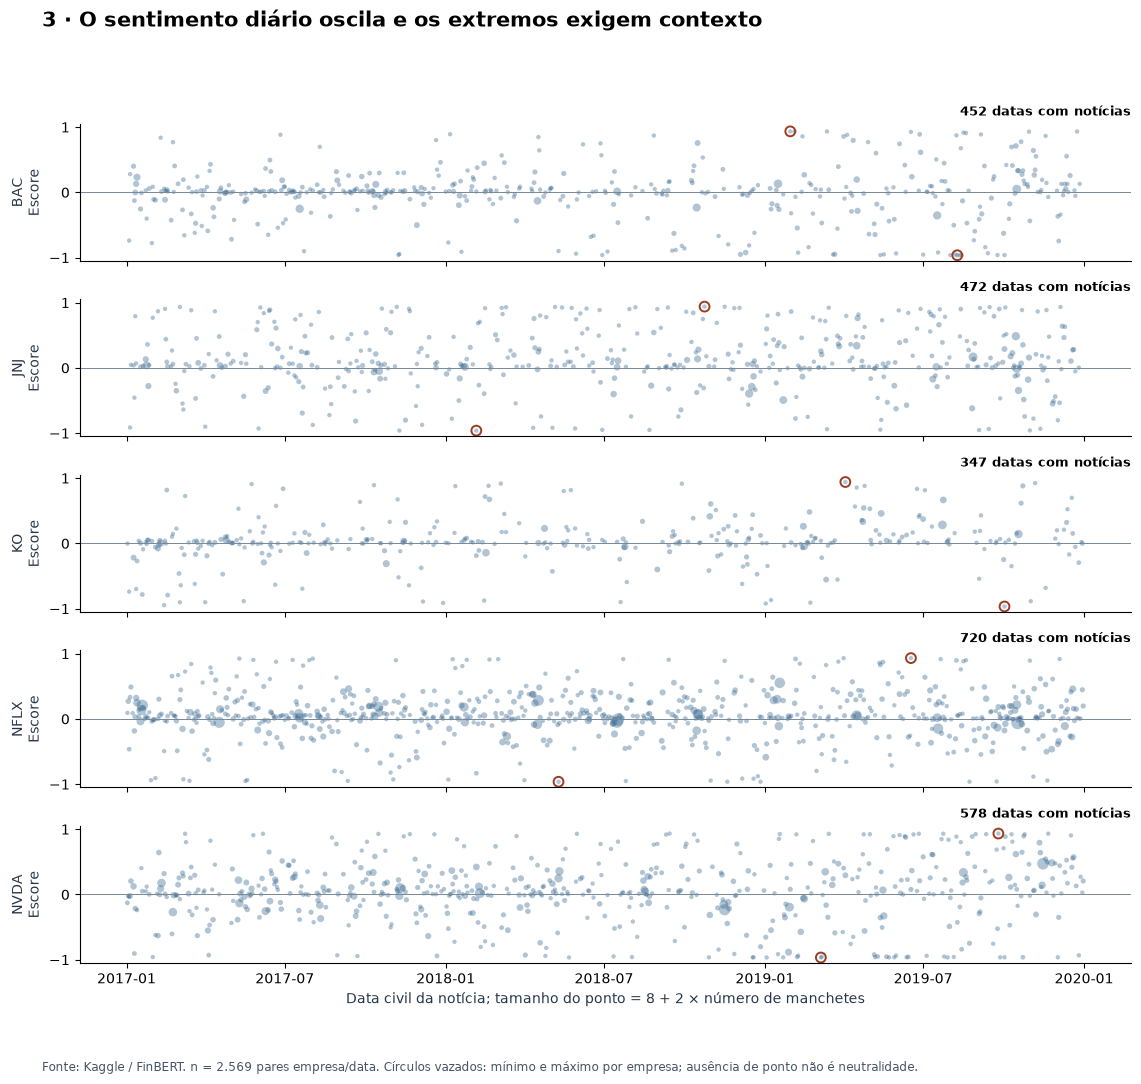

,stock,news_date,escore,n_noticias,extremo
0,BAC,2019-08-09,-0.963682,1,mínimo
1,BAC,2019-01-30,0.934606,1,máximo
2,JNJ,2018-02-05,-0.961099,1,mínimo
3,JNJ,2018-10-24,0.938982,1,máximo
4,KO,2019-10-02,-0.966257,1,mínimo
5,KO,2019-04-03,0.940817,1,máximo
6,NFLX,2018-05-10,-0.962488,1,mínimo
7,NFLX,2019-06-17,0.932194,1,máximo
8,NVDA,2019-03-06,-0.965972,1,mínimo
9,NVDA,2019-09-25,0.933611,1,máximo


In [6]:
diario = noticias.groupby(['stock','news_date'],as_index=False).agg(escore=('escore_sentimento','mean'),n_noticias=('headline','size'))
assert len(diario)==2569
extremos=[]
for empresa,g in diario.groupby('stock',sort=True):
    for tipo,asc in [('mínimo',True),('máximo',False)]:
        linha=g.sort_values(['escore','news_date'],ascending=[asc,True]).iloc[0].to_dict()
        linha['extremo']=tipo; extremos.append(linha)
extremos=pd.DataFrame(extremos)
fig,axs=plt.subplots(5,1,figsize=(12,11),sharex=True,sharey=True)
for ax,empresa in zip(axs,EMPRESAS):
    g=diario.loc[diario['stock'].eq(empresa)]
    ax.scatter(g['news_date'],g['escore'],s=8+2*g['n_noticias'],alpha=.38,color='#32648D',linewidths=0)
    ex=extremos.loc[extremos['stock'].eq(empresa)]
    ax.scatter(ex['news_date'],ex['escore'],s=50,facecolors='none',edgecolors='#9C3D22',linewidths=1.4)
    ax.axhline(0,color='#778899',lw=.7); ax.set_ylim(-1.05,1.05)
    ax.set_ylabel(f'{empresa}\nEscore'); ax.set_title(f'{len(g)} datas com notícias',loc='right',fontsize=9)
axs[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
axs[-1].set_xlabel('Data civil da notícia; tamanho do ponto = 8 + 2 × número de manchetes')
salvar(fig,'q3_evolucao','3 · O sentimento diário oscila e os extremos exigem contexto',
       'Fonte: Kaggle / FinBERT. n = 2.569 pares empresa/data. Círculos vazados: mínimo e máximo por empresa; ausência de ponto não é neutralidade.')
display(extremos)

## 7. Pergunta 3 · Rastrear as manchetes dos extremos
Uma junção `many_to_one` devolve a cada manchete a identificação do extremo de seu grupo. Exportamos **todas** as manchetes dessas dez datas/empresas. A leitura deve separar o que o texto relata daquilo que o classificador atribui; não buscamos explicações externas a partir da coincidência com preços. O artigo resume esses textos e a quantidade de notícias que sustenta cada extremo.

In [7]:
textos_extremos = noticias.merge(extremos[['stock','news_date','extremo']],on=['stock','news_date'],how='inner',validate='many_to_one')
textos_extremos = textos_extremos[['stock','news_date','extremo','source_row','headline','url','classe_finbert','escore_sentimento']].sort_values(['stock','news_date','source_row'])
assert len(textos_extremos)==int(extremos['n_noticias'].sum())
with pd.option_context('display.max_colwidth',160,'display.max_rows',40):
    display(textos_extremos[['stock','news_date','extremo','headline','escore_sentimento']])

,stock,news_date,extremo,headline,escore_sentimento
0,BAC,2019-01-30,máximo,PACCAR's Forecast Sees A Slightly Growth In Class 8 Truck Market After A Strong Year,0.934606
1,BAC,2019-08-09,mínimo,Shares of several blue-chip stocks are trading lower in sympathy with the overall market.,-0.963682
2,JNJ,2018-02-05,mínimo,"J&J Shares Fall 3.5%, Quickly Rebound From Lows But Still Down ~2.5% For Session; Traders Circulate Mesothelioma.net Article 'Johnson & Johnson Mesothelioma...",-0.961099
3,JNJ,2018-10-24,máximo,Janssen's Stelara Demonstrated Sustained Efficiency In Improving Clinical Remission Rates In Chron's Patients Throughout Three Years; Safety Events Were Not...,0.938982
4,KO,2019-04-03,máximo,Guggenheim Referencing Nielsen Data Notes Coca-Cola 'Total sales increased +2.5% in the 12-wks with CSD sales increasing +5.1% as the company continues to b...,0.940817
5,KO,2019-10-02,mínimo,Coca-Cola Co shares are trading lower in sympathy with the overall market amid global recession concerns.,-0.966257
6,NFLX,2018-05-10,mínimo,"Netflix Shares Down ~0.7% Over Last Few Mins., Now Rebounding From $328 Level; Stock Down 0.5% For Session; Not Seeing News To Justify Move Lower",-0.962488
7,NFLX,2019-06-17,máximo,Netflix shares are trading higher on reports of positive subscriber trends.,0.932194
8,NVDA,2019-03-06,mínimo,Semiconductor Industry Association Reports 7.2% Decline in Global Chip Sales in January,-0.965972
9,NVDA,2019-09-25,máximo,NVIDIA shares are trading higher despite no company-specific news. The stock has rallied roughly 14% in the past 3 months.,0.933611


**Resultado e contexto.** Os dez extremos têm uma manchete cada. BAC/máximo menciona PACCAR, evidenciando uma associação indireta de ticker; diversos outros textos descrevem movimentos já ocorridos. A leitura textual detalhada e os limites estão na pergunta 3 do artigo. Não excluímos esses registros.

## 8. Pergunta 4 · Distribuições do retorno por classe
Usamos uma linha por empresa/pregão elegível. `agg` produz n, média, mediana e quartis. A caixa vai de Q1 a Q3; a linha é a mediana; os bigodes alcançam as observações dentro de 1,5 vezes o intervalo interquartil; pontos mostram os valores além dos bigodes. Não removemos os extremos. Escala vertical comum e n junto aos rótulos tornam diferenças e desequilíbrios visíveis.

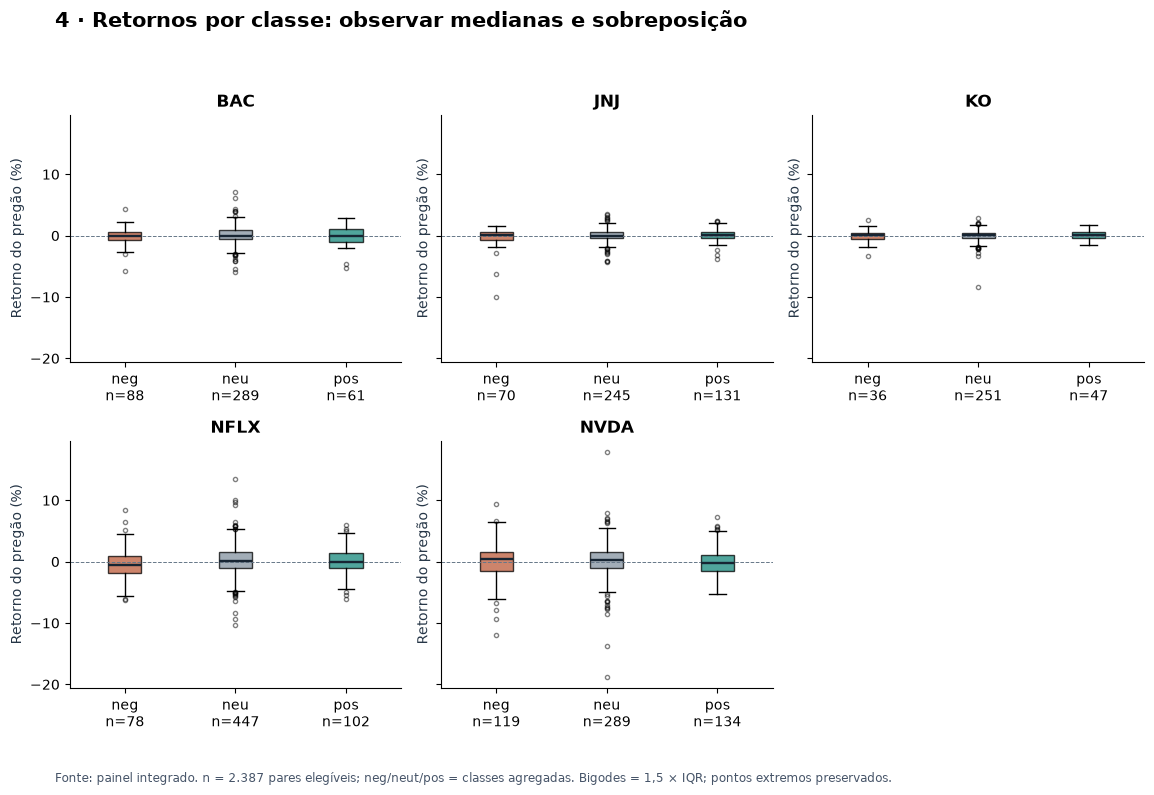

,stock,classe_sentimento,n,media,mediana,q1,q3,minimo,maximo
0,BAC,negativo,88,-0.138,0.000,-0.731,0.621,-5.810,4.354
1,BAC,neutro,289,0.129,0.000,-0.565,0.938,-5.919,7.156
2,BAC,positivo,61,-0.038,-0.061,-1.078,1.156,-5.290,2.800
3,JNJ,negativo,70,-0.244,0.092,-0.634,0.517,-10.038,1.586
4,JNJ,neutro,245,0.028,0.000,-0.435,0.600,-4.259,3.545
5,JNJ,positivo,131,0.142,0.163,-0.380,0.614,-3.850,2.340
6,KO,negativo,36,-0.027,0.095,-0.595,0.468,-3.384,2.518
7,KO,neutro,251,0.001,0.090,-0.400,0.470,-8.435,2.899
8,KO,positivo,47,0.057,0.087,-0.444,0.634,-1.486,1.805
9,NFLX,negativo,78,-0.485,-0.498,-1.776,0.835,-6.271,8.462


In [8]:
def resumir_classes(df):
    return df.groupby(['stock','classe_sentimento'],observed=True)['retorno_pct'].agg(
        n='size',media='mean',mediana='median',q1=lambda s:s.quantile(.25),q3=lambda s:s.quantile(.75),minimo='min',maximo='max').reset_index()
retornos_classes = resumir_classes(principal)
fig,axs=plt.subplots(2,3,figsize=(12,8),sharey=True)
for ax,empresa in zip(axs.flat,EMPRESAS):
    g=principal.loc[principal['stock'].eq(empresa)]
    presentes=[c for c in CLASSES if g['classe_sentimento'].eq(c).any()]
    valores=[g.loc[g['classe_sentimento'].eq(c),'retorno_pct'] for c in presentes]
    box=ax.boxplot(valores,patch_artist=True,tick_labels=[f'{c[:3]}\nn={len(v)}' for c,v in zip(presentes,valores)],
        medianprops={'color':'#172533','linewidth':1.7},flierprops={'markersize':3,'alpha':.5})
    for patch,c in zip(box['boxes'],presentes): patch.set_facecolor(CORES[c]); patch.set_alpha(.75)
    ax.axhline(0,color='#667788',ls='--',lw=.7); ax.set_title(empresa); ax.set_ylabel('Retorno do pregão (%)')
axs.flat[-1].axis('off')
salvar(fig,'q4_retornos_classes','4 · Retornos por classe: observar medianas e sobreposição',
       'Fonte: painel integrado. n = 2.387 pares elegíveis; neg/neut/pos = classes agregadas. Bigodes = 1,5 × IQR; pontos extremos preservados.')
display(retornos_classes.round(3))

**Resultado e interpretação.** As distribuições se sobrepõem e não exibem uma ordenação positiva > neutra > negativa comum às cinco empresas. Em NFLX, a mediana é −0,498% na classe negativa e +0,015% na positiva; em NVDA, a relação se inverte: +0,382% e −0,173%, respectivamente. Em JNJ, as medianas de negativo e positivo são ambas positivas. A dispersão dentro das classes é relevante, especialmente em NFLX e NVDA. Assim, o rótulo de sentimento não separa os retornos de forma uniforme neste recorte.

**Limitação.** Tamanhos diferentes, casos extremos, notícias retrospectivas e ausência de horários limitam a leitura. Em JNJ/negativo, por exemplo, a média é negativa (−0,244%), embora a mediana seja positiva (+0,092%), mostrando por que o centro depende da medida. Diferenças observadas não demonstram significância estatística, previsibilidade fora da amostra ou efeito causal.

## 9. Pergunta 5 · Quantidade, intensidade e oscilação
Cada ponto é um pregão com notícias e janela completa. Os dois conjuntos usam a mesma escala vertical e preservam os maiores retornos absolutos. A intensidade é o módulo do **escore médio**, podendo diminuir quando tons opostos se compensam. As correlações de Spearman descrevem ordenação monotônica; não testam significância e não medem efeitos causais.

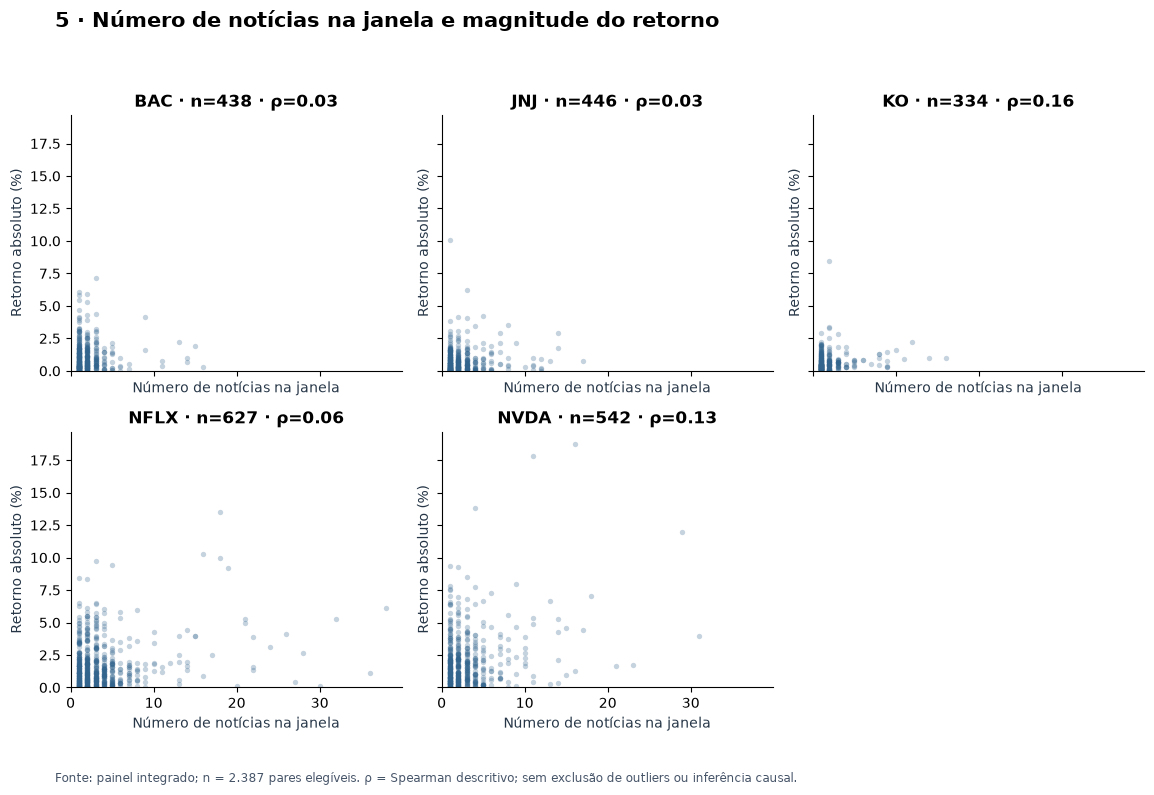

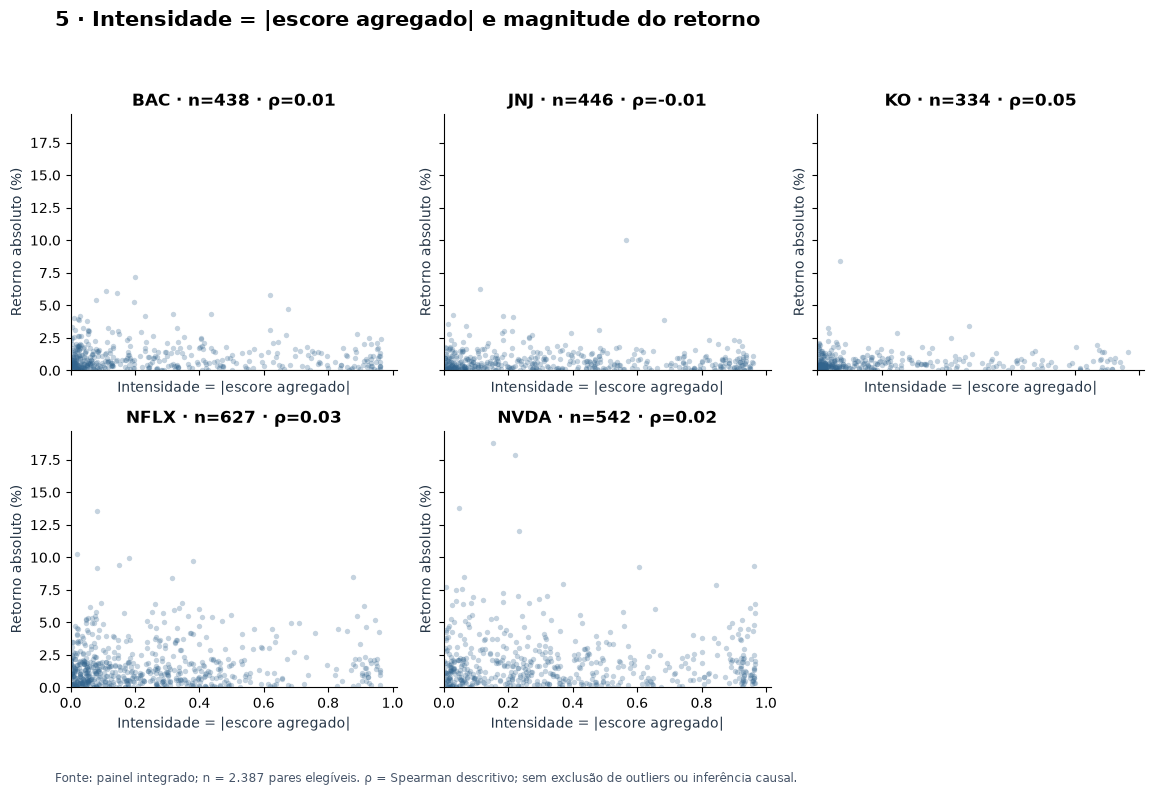

,stock,n,rho_quantidade_abs,rho_intensidade_abs
0,BAC,438,0.0327,0.0112
1,JNJ,446,0.0297,-0.0097
2,KO,334,0.1608,0.0548
3,NFLX,627,0.0570,0.0301
4,NVDA,542,0.1252,0.0160


In [9]:
associacoes_q5=[]
for empresa,g in principal.groupby('stock'):
    associacoes_q5.append({'stock':empresa,'n':len(g),
        'rho_quantidade_abs':spearman(g,'n_noticias','retorno_absoluto_pct'),
        'rho_intensidade_abs':spearman(g,'intensidade_sentimento','retorno_absoluto_pct')})
associacoes_q5=pd.DataFrame(associacoes_q5)
for x,nome,rotulo in [('n_noticias','q5_quantidade','Número de notícias na janela'),
                       ('intensidade_sentimento','q5_intensidade','Intensidade = |escore agregado|')]:
    fig,axs=plt.subplots(2,3,figsize=(12,8),sharex=True,sharey=True)
    for ax,empresa in zip(axs.flat,EMPRESAS):
        g=principal.loc[principal['stock'].eq(empresa)]
        ax.scatter(g[x],g['retorno_absoluto_pct'],s=15,alpha=.28,color='#32648D',linewidths=0)
        ax.set_title(f'{empresa} · n={len(g)} · ρ={spearman(g,x,"retorno_absoluto_pct"):.2f}')
        ax.set_xlabel(rotulo); ax.set_ylabel('Retorno absoluto (%)'); ax.set_ylim(0,principal['retorno_absoluto_pct'].max()*1.05); ax.set_xlim(0,principal[x].max()*1.05)
    axs.flat[-1].axis('off')
    salvar(fig,nome,f'5 · {rotulo} e magnitude do retorno',
           'Fonte: painel integrado; n = 2.387 pares elegíveis. ρ = Spearman descritivo; sem exclusão de outliers ou inferência causal.')
display(associacoes_q5.round(4))

**Resultado e interpretação.** Quantidade e retorno absoluto têm coeficientes positivos de 0,030 a 0,161, maiores em KO (0,161) e NVDA (0,125), ainda com grande dispersão. Para intensidade, os coeficientes variam de −0,010 a +0,055, próximos de zero. **H2 não recebe apoio descritivo claro nesta operacionalização:** maior intensidade líquida não acompanha uma elevação consistente da magnitude posterior.

**Limitação.** O módulo do escore médio permite compensação de manchetes opostas e não equivale à média das intensidades individuais. Correlação próxima de zero não exclui relações não monotônicas. Retorno absoluto mede oscilação diária, não volatilidade formal. Cobertura pode ser maior justamente em contextos turbulentos, sem identificar direção causal.

## 10. Pergunta 6 · Escore e retorno por empresa e ano
O ano vem do pregão de resposta. Calculamos Spearman em cada empresa/ano e no período completo; todas as células trazem n. A escala de cor fica fixa em −1 a 1 para não exagerar coeficientes pequenos. As dispersões complementam o mapa: uma correlação resume a nuvem e não substitui sua inspeção.

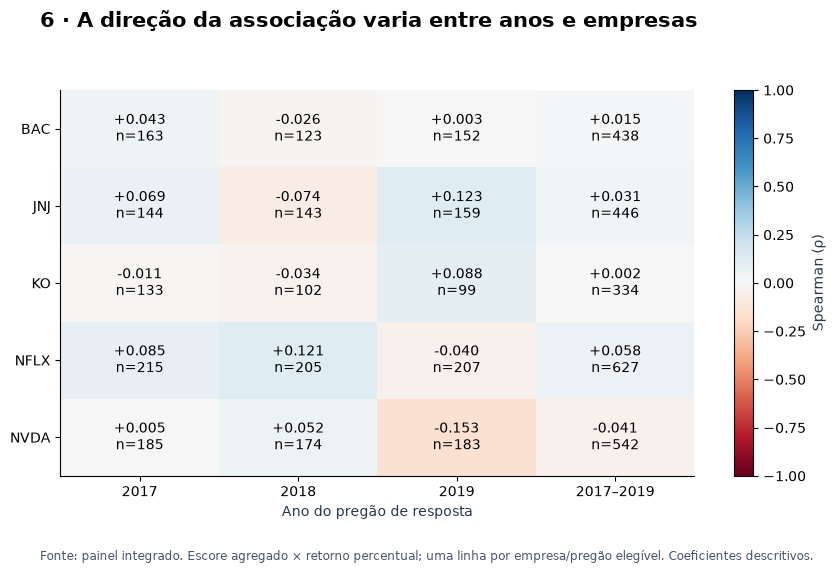

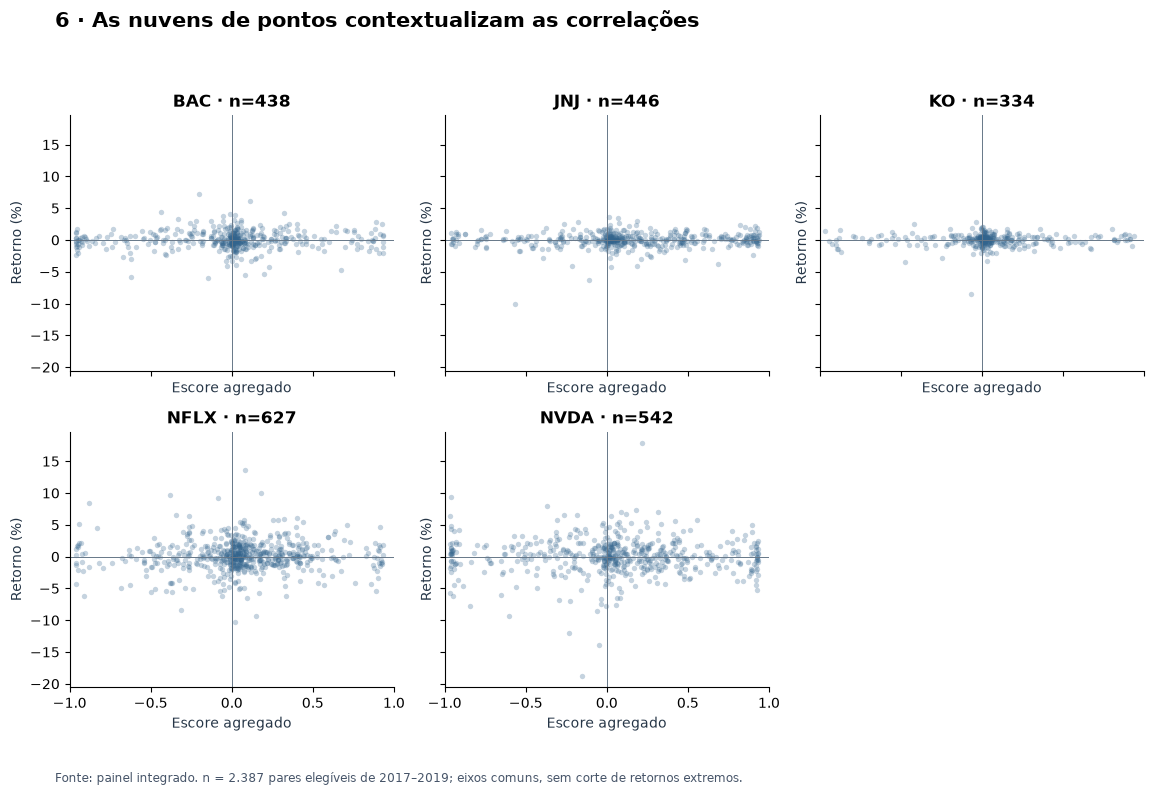

,stock,periodo,n,rho
0,BAC,2017–2019,438,0.0150
1,BAC,2017,163,0.0428
2,BAC,2018,123,-0.0259
3,BAC,2019,152,0.0033
4,JNJ,2017–2019,446,0.0307
5,JNJ,2017,144,0.0691
6,JNJ,2018,143,-0.0745
7,JNJ,2019,159,0.1226
8,KO,2017–2019,334,0.0023
9,KO,2017,133,-0.0107


In [10]:
correlacoes=[]
for empresa,g in principal.groupby('stock'):
    for periodo,h in [('2017–2019',g)]+[(str(a),h) for a,h in g.groupby('ano')]:
        correlacoes.append({'stock':empresa,'periodo':periodo,'n':len(h),'rho':spearman(h,'escore_sentimento','retorno_pct')})
correlacoes=pd.DataFrame(correlacoes)
periodos=['2017','2018','2019','2017–2019']
mat=correlacoes.pivot(index='stock',columns='periodo',values='rho').reindex(index=EMPRESAS,columns=periodos)
ns=correlacoes.pivot(index='stock',columns='periodo',values='n').reindex(index=EMPRESAS,columns=periodos)
fig,ax=plt.subplots(figsize=(9,5.7))
im=ax.imshow(mat,cmap='RdBu',vmin=-1,vmax=1,aspect='auto')
for i in range(5):
    for j in range(4): ax.text(j,i,f'{mat.iloc[i,j]:+.3f}\nn={ns.iloc[i,j]}',ha='center',va='center',fontsize=10)
ax.set_xticks(range(4),periodos); ax.set_yticks(range(5),EMPRESAS)
ax.set_xlabel('Ano do pregão de resposta'); fig.colorbar(im,ax=ax,label='Spearman (ρ)')
salvar(fig,'q6_correlacoes','6 · A direção da associação varia entre anos e empresas',
       'Fonte: painel integrado. Escore agregado × retorno percentual; uma linha por empresa/pregão elegível. Coeficientes descritivos.')
fig,axs=plt.subplots(2,3,figsize=(12,8),sharex=True,sharey=True)
for ax,empresa in zip(axs.flat,EMPRESAS):
    g=principal.loc[principal['stock'].eq(empresa)]
    ax.scatter(g['escore_sentimento'],g['retorno_pct'],s=15,alpha=.28,color='#32648D',linewidths=0)
    ax.axhline(0,color='#667788',lw=.7); ax.axvline(0,color='#667788',lw=.7)
    ax.set_title(f'{empresa} · n={len(g)}'); ax.set_xlim(-1,1)
    ax.set_xlabel('Escore agregado'); ax.set_ylabel('Retorno (%)')
axs.flat[-1].axis('off')
salvar(fig,'q6_dispersoes','6 · As nuvens de pontos contextualizam as correlações',
       'Fonte: painel integrado. n = 2.387 pares elegíveis de 2017–2019; eixos comuns, sem corte de retornos extremos.')
display(correlacoes.round(4))

**Resultado e interpretação.** No período completo, ρ varia de −0,041 (NVDA) a +0,058 (NFLX), próximo de zero nas cinco empresas. Entre os 15 grupos anuais, vai de −0,153 (NVDA/2019) a +0,123 (JNJ/2019). NFLX passa de +0,121 em 2018 a −0,040 em 2019; JNJ passa de −0,074 a +0,123. H3 encontra variação descritiva de sinal e magnitude, mas os coeficientes pequenos **não demonstram uma diferença estrutural** entre anos ou empresas. A resposta inicial é de associações fracas e instáveis neste recorte.

**Limitação.** Não foram realizados testes de diferença entre coeficientes, intervalos de confiança ou validação temporal. Dependência temporal, manchetes compartilhadas e grupos de tamanhos diferentes impedem interpretar as células como estimativas independentes ou confirmar uma relação generalizável.

## 11. Pergunta 7 · Primeira sensibilidade: mínimo de três notícias
O filtro é aplicado **depois** da seleção da amostra principal, na contagem por pregão. Nenhuma manchete é excluída individualmente neste cenário, portanto não é necessário recalcular o escore dos pregões retidos. Comparamos as três associações anteriores e as distribuições por classe, preservando os denominadores. Esse subconjunto não é independente da amostra principal, e a mudança pode decorrer da seleção de pregões mais cobertos. A etapa ainda não testa exclusão de retrospectivas nem filtros combinados.

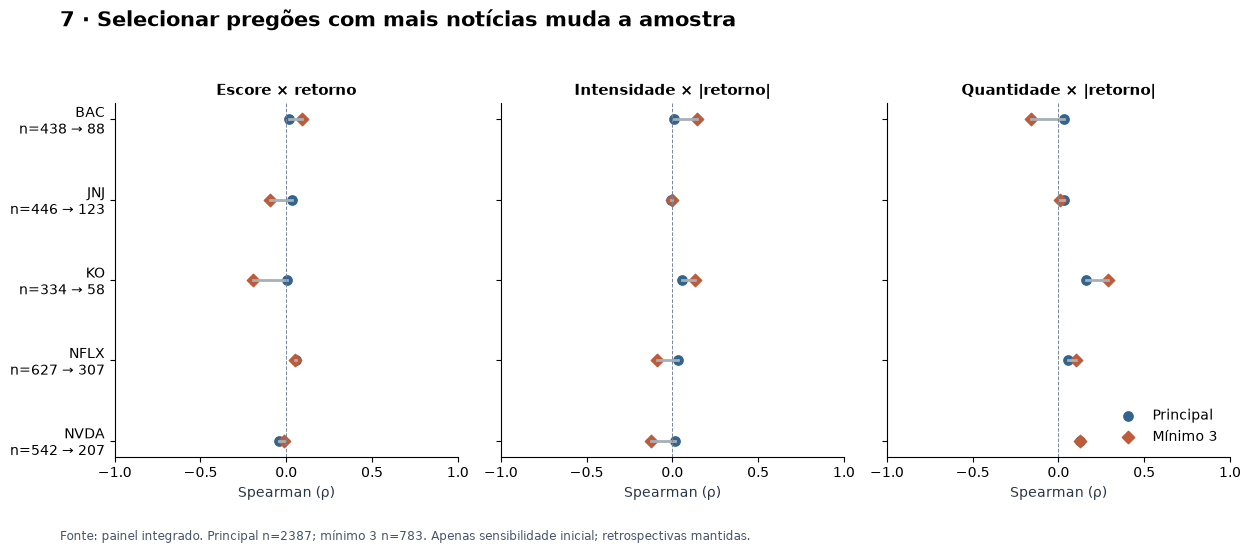

,principal,minimo_3,retencao_pct
stock,,,
BAC,438,88,20.09
JNJ,446,123,27.58
KO,334,58,17.37
NFLX,627,307,48.96
NVDA,542,207,38.19


,cenario,stock,metrica,n,rho
0,Principal,BAC,Escore × retorno,438,0.0150
1,Principal,BAC,Intensidade × |retorno|,438,0.0112
2,Principal,BAC,Quantidade × |retorno|,438,0.0327
3,Principal,JNJ,Escore × retorno,446,0.0307
4,Principal,JNJ,Intensidade × |retorno|,446,-0.0097
5,Principal,JNJ,Quantidade × |retorno|,446,0.0297
6,Principal,KO,Escore × retorno,334,0.0023
7,Principal,KO,Intensidade × |retorno|,334,0.0548
8,Principal,KO,Quantidade × |retorno|,334,0.1608
9,Principal,NFLX,Escore × retorno,627,0.0575


In [11]:
restrita=principal.loc[principal['n_noticias'].ge(3)].copy()
metricas=[('escore_sentimento','retorno_pct','Escore × retorno'),
          ('intensidade_sentimento','retorno_absoluto_pct','Intensidade × |retorno|'),
          ('n_noticias','retorno_absoluto_pct','Quantidade × |retorno|')]
sensibilidade=[]
classes_sensibilidade=[]
for cenario,df in [('Principal',principal),('Mínimo 3',restrita)]:
    classes_sensibilidade.append(resumir_classes(df).assign(cenario=cenario))
    for empresa,g in df.groupby('stock'):
        for x,y,metrica in metricas:
            sensibilidade.append({'cenario':cenario,'stock':empresa,'metrica':metrica,'n':len(g),'rho':spearman(g,x,y)})
sensibilidade=pd.DataFrame(sensibilidade)
classes_sensibilidade=pd.concat(classes_sensibilidade,ignore_index=True)
fig,axs=plt.subplots(1,3,figsize=(13,5.5),sharey=True)
for ax,(_,_,metrica) in zip(axs,metricas):
    for i,empresa in enumerate(EMPRESAS):
        g=sensibilidade.loc[sensibilidade['metrica'].eq(metrica)&sensibilidade['stock'].eq(empresa)].set_index('cenario')
        a,b=g.loc['Principal','rho'],g.loc['Mínimo 3','rho']
        ax.plot([a,b],[i,i],color='#A6B0B8',lw=2)
        ax.scatter(a,i,color='#32648D',s=45,label='Principal' if i==0 else None)
        ax.scatter(b,i,color='#BD5B3A',marker='D',s=40,label='Mínimo 3' if i==0 else None)
    ax.axvline(0,color='#778899',ls='--',lw=.7); ax.set_xlim(-1,1); ax.set_xticks([-1,-.5,0,.5,1]); ax.set_xlabel('Spearman (ρ)'); ax.set_title(metrica,fontsize=11)
axs[0].set_yticks(range(5),[f'{e}\nn={amostras.loc[e,"principal"]} → {amostras.loc[e,"minimo_3"]}' for e in EMPRESAS])
axs[0].invert_yaxis(); axs[-1].legend(loc='lower right',frameon=False)
salvar(fig,'q7_minimo_tres','7 · Selecionar pregões com mais notícias muda a amostra',
       f'Fonte: painel integrado. Principal n={len(principal)}; mínimo 3 n={len(restrita)}. Apenas sensibilidade inicial; retrospectivas mantidas.')
display(amostras[['principal','minimo_3','retencao_pct']].round(2))
display(sensibilidade.round(4))

**Resultado e interpretação.** Restam 783 pares (32,8% da amostra principal). A retenção vai de 17,4% em KO a 49,0% em NFLX, alterando a composição. Em KO, escore × retorno passa de +0,002 a −0,196 (n de 334 para 58); em JNJ, de +0,031 a −0,095. Em NFLX, fica próximo: +0,058 e +0,051. Para intensidade × retorno absoluto, NFLX passa de +0,030 a −0,088 e NVDA de +0,016 a −0,122. Os resultados não mostram um padrão de sinal estável em todas as empresas. O filtro também restringe a amplitude de contagens, afetando a comparação quantidade × retorno absoluto.

**O que permanece pendente.** A pergunta 7 está parcialmente respondida. Não excluímos retrospectivas nem testamos os filtros combinados. O planejamento define retrospectiva como manchete que relata movimento de preço já ocorrido; falta operacionalizar e revisar os casos, com critérios de ambiguidade. A marcação deve ser feita sem consultar o efeito da exclusão nos retornos. Depois será necessário reagrupar as manchetes remanescentes e reaplicar o mínimo de três sobre a nova contagem. Retenção desigual e amostra menor também podem explicar mudanças; não declaramos robustez completa.

## 12. Exportar tabelas, registrar origem e fechar as verificações
Cada gráfico tem uma tabela de apoio. O manifesto registra hashes das entradas, versões e tamanhos; a execução gera os resultados, sem números preenchidos manualmente. Os CSVs de resumos ficam versionados; a listagem de textos extremos fica no pacote local. As bases das etapas anteriores e a revisão humana permanecem intactas.

**Próximas melhorias:** revisar a interpretação dos extremos com outro integrante; definir/revisar a marcação de retrospectivas sem consultar o impacto nos retornos; depois retirar manchetes, reagrupar por pregão e reaplicar o mínimo de três às restantes. Reavaliar a composição por empresa/ano e limitações de dependência. Não há conclusão causal nem alegação de robustez completa.

In [12]:
tabelas={'amostras':amostras.reset_index(),'q1_cobertura_mensal':cobertura.reset_index(),
         'q2_classes':classes.reset_index(),'q2_proporcoes':proporcoes.reset_index(),
         'q3_diario':diario,'q3_extremos':extremos,
         'q4_retornos_classes':retornos_classes,'q5_associacoes':associacoes_q5,
         'q6_correlacoes':correlacoes,'q7_sensibilidade':sensibilidade,
         'q7_retornos_classes':classes_sensibilidade}
for nome,tabela in tabelas.items(): tabela.to_csv(TAB/f'{nome}.csv',index=False,float_format='%.10g')
textos_extremos.to_csv(DATA/'manchetes_extremos_analise.csv',index=False)
manifesto={'executado_em_utc':datetime.now(timezone.utc).isoformat(),'etapa_planejada':'20-23/10/2026',
           'commit_base':CONFIG['commit_base'],'sha256_entradas':CONFIG['sha256_entradas'],
           'n_noticias':len(noticias),'n_painel':len(painel),'n_principal':len(principal),
           'n_minimo_3':len(restrita),'n_datas_civis':len(diario),'n_textos_extremos':len(textos_extremos),
           'figuras':figuras,'tabelas':list(tabelas),'retrospectivas_excluidas':False,
           'versoes':{'python':platform.python_version(),'pandas':pd.__version__,
                       'numpy':np.__version__,'matplotlib':matplotlib.__version__}}
manifesto['sha256_tabelas']={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in TAB.glob('*.csv')}
(TAB/'manifesto.json').write_text(json.dumps(manifesto,ensure_ascii=False,indent=2),encoding='utf-8')
for nome,esperado in CONFIG['sha256_entradas'].items():
    assert hashlib.sha256((DATA/nome).read_bytes()).hexdigest()==esperado
assert len(figuras)==9 and len(set(figuras))==9
print(f'Concluído: {len(figuras)} figuras, {len(tabelas)} tabelas e manifesto. Entradas preservadas.')

Concluído: 9 figuras, 11 tabelas e manifesto. Entradas preservadas.
